# Self-organizing maps

Kohonen's self-organizing map (SOM; "Self-organized formation of topologically correct feature maps", 1982) lays data on a grid of units so that neighboring units hold similar data. Its classic demonstration sorts random colors onto a square. This notebook repeats that, then maps the Pokémon base stats, and asks what the map keeps and what it loses, with the same rank scores used for t-SNE.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from maps import colors, data, ranks, som, study

plt.rcParams["figure.dpi"] = 80

## Vocabulary

- A **map** is a grid of **units**; each unit holds a **weight**, a point in data space.
- The **best-matching unit** of a data point is the unit whose weight is closest to it.
- A training **step** draws one data point x, finds its best-matching unit b, and moves every unit u toward x:

  w_u ← w_u + α(t) · exp(−|u − b|² / 2σ(t)²) · (x − w_u),

  where |u − b| is distance on the grid. The step size α and the neighborhood width σ shrink over training (here geometrically, α from 0.5 to 0.01 and σ from half the grid's side to 0.5). Early on, a step drags a large patch of the map, which orders it; late steps move single units, which fits it to the data.

## Colors

1,000 random sRGB colors (seed 0) are the data, three numbers each. The map is 20 × 20 units, started from random data points (seed 1) and trained for 20,000 steps. Each unit is painted with its own weight.

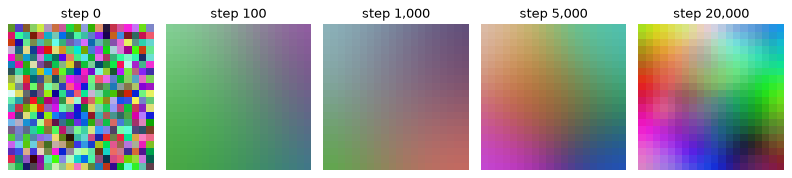

In [2]:
cmap, cx = study.color_map()
fig, axes = plt.subplots(1, len(study.COLOR_SNAPSHOTS), figsize=(10, 2.3))
for ax, t in zip(axes, study.COLOR_SNAPSHOTS, strict=True):
    ax.imshow(cmap.history[t].reshape(*study.COLOR_SHAPE, 3).clip(0, 1), interpolation="nearest")
    ax.set_title(f"step {t:,}")
    ax.axis("off")
fig.tight_layout()

At step 0 the units are random colors. After 100 steps, with σ still near 10, every step has dragged most of the map, so all units sit near the mean color: the map is a smooth, washed-out gradient, ordered but not fitted. As σ and α shrink, the units spread back out toward the data, and by step 20,000 the edges hold strong colors and the map has its final layout.

Two standard measures of a trained map: the **quantization error**, the mean distance from each data point to its best unit's weight; and the **topographic error** (Kiviluoto 1996), the share of data points whose closest and second-closest units are not grid neighbors.

In [3]:
print(f"quantization error {som.quantization_error(cmap, cx):.4f} (sRGB units; the colors' mean distance to their centroid is {np.linalg.norm(cx - cx.mean(axis=0), axis=1).mean():.3f})")
print(f"topographic error {som.topographic_error(cmap, cx):.3f}")

quantization error 0.0830 (sRGB units; the colors' mean distance to their centroid is 0.482)
topographic error 0.091


## Pokémon

The 705 distinct stat lines (raw stats, as in the t-SNE notebook) on a 16 × 16 map, started on the plane of the first two principal components and trained for 40,000 steps. A **component plane** paints each unit by one coordinate of its weight: here, one stat. The **U-matrix** paints each unit by its mean distance to its grid neighbors, so light ridges mark borders between groups.

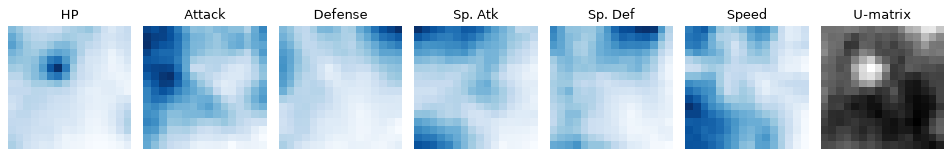

In [4]:
pmap, px = study.pokemon_map()
fig, axes = plt.subplots(1, 7, figsize=(12, 2.2))
for c, (ax, stat) in enumerate(zip(axes, data.STATS, strict=False)):
    ax.imshow(pmap.weights[:, c].reshape(study.POKE_SHAPE), cmap="Blues")
    ax.set_title(stat)
    ax.axis("off")
axes[-1].imshow(som.u_matrix(pmap, study.POKE_SHAPE), cmap="Greys_r")
axes[-1].set_title("U-matrix")
axes[-1].axis("off")
fig.tight_layout()

In [5]:
names, _, _ = data.pokemon()
pos = som.positions(pmap, px)
for who in ("Shuckle", "Blissey", "Chansey", "Mewtwo", "Ninjask", "Magikarp", "Pikachu", "Snorlax"):
    i = names.index(who)
    print(f"{who:9} unit (row {int(pos[i, 0])}, column {int(pos[i, 1])})  stats {px[i].astype(int).tolist()}")

Shuckle   unit (row 0, column 13)  stats [20, 10, 230, 10, 230, 5]
Blissey   unit (row 5, column 6)  stats [255, 10, 10, 75, 135, 55]
Chansey   unit (row 5, column 6)  stats [250, 5, 5, 35, 105, 50]
Mewtwo    unit (row 0, column 1)  stats [106, 110, 90, 154, 90, 130]
Ninjask   unit (row 10, column 0)  stats [61, 90, 45, 50, 50, 160]
Magikarp  unit (row 15, column 11)  stats [20, 10, 55, 15, 20, 80]
Pikachu   unit (row 14, column 9)  stats [35, 55, 40, 50, 50, 90]
Snorlax   unit (row 5, column 5)  stats [160, 110, 65, 65, 110, 30]


The component planes show what the map keeps: each stat changes smoothly across the grid. High Attack sits on the left, high Special Attack along the top, high Speed at the bottom left. High HP is a small island inside the map: Chansey and Blissey share one unit there, beside Snorlax. The U-matrix rings that island with a bright border, because its units are far from their neighbors in stat space: the grid had no room to put this group at an edge. The other named Pokémon land where their stats say: Shuckle (Defense and Special Defense 230) on the top edge, Mewtwo near the top-left corner, Ninjask (Speed 160) on the left edge, Magikarp and Pikachu along the bottom.

## What it keeps and loses

On a SOM, several Pokémon share a unit, so a point has many tied neighbors on the map. Venna and Kaski scored such maps by ordering the tied points in the best and the worst way and averaging. The range between the two is part of the answer: a point's neighbors within its own unit are not ordered at all.

In [6]:
tc = ranks.trust_continuity(colors.distances(px), colors.distances(pos), study.KS)
som_res = study.som_section()
sne_res = study.stored()["sne"]["pokemon"]
print(f"units used: {som_res['pokemon']['units_used']} of {np.prod(study.POKE_SHAPE)};  quantization error {som_res['pokemon']['quantization_error']:.1f};  topographic error {som_res['pokemon']['topographic_error']:.3f}\n")
print(f"{'':16} {'T(5)':>6} {'T(10)':>6} {'T(20)':>6} {'C(5)':>6} {'C(10)':>6} {'C(20)':>6}")
print(f"{'SOM, best ties':16} " + " ".join(f"{v:6.3f}" for v in tc["trust_best"] + tc["cont_best"]))
print(f"{'SOM, worst ties':16} " + " ".join(f"{v:6.3f}" for v in tc["trust_worst"] + tc["cont_worst"]))
print(f"{'SOM, average':16} " + " ".join(f"{v:6.3f}" for v in tc["trust"] + tc["cont"]))
for label in ("PCA", "SNE", "t-SNE"):
    r = sne_res[label]
    print(f"{label:16} " + " ".join(f"{v:6.3f}" for v in r["T"] + r["C"]))

units used: 240 of 256;  quantization error 21.9;  topographic error 0.105

                   T(5)  T(10)  T(20)   C(5)  C(10)  C(20)
SOM, best ties    0.990  0.981  0.969  0.936  0.921  0.903
SOM, worst ties   0.935  0.953  0.945  0.926  0.913  0.895
SOM, average      0.963  0.967  0.957  0.931  0.917  0.899
PCA               0.863  0.865  0.868  0.962  0.957  0.952
SNE               0.887  0.886  0.885  0.974  0.968  0.959
t-SNE             0.982  0.966  0.947  0.965  0.952  0.938


The SOM is more trustworthy than PCA and SNE, and less continuous than all three others, even in its best tie order. Venna and Kaski (2001) found the same ordering of SOMs against multidimensional-scaling methods on three other data sets: points shown together on a SOM are similar, but similar points are often shown apart, because the grid has edges and a fixed shape. t-SNE matches the SOM's average trustworthiness at k = 10 (0.966 against 0.967) and keeps more of the data's neighborhoods (continuity 0.952 against 0.917).

The tie range is wide at k = 5: with 705 points on 256 units, about three Pokémon share a unit, so the five nearest on the map are often decided by the tie order alone.

## Variations and open questions

- **Grid size.** A larger grid has fewer ties and more empty units. How T and C move with grid size, from 8 × 8 to 40 × 40, is a sweep that costs seconds.
- **Batch SOM.** Kohonen's batch algorithm replaces the random steps by averages over all data and is deterministic given its start. Does it reach the same scores?
- **A hexagonal grid** gives each unit six neighbors instead of four, which Kohonen recommends for visual inspection.
- **What the corners mean.** Do the units at the corners hold real Pokémon, or interpolations between groups? Counting data points per unit (the hit histogram) answers it.

## The numbers the README quotes

In [7]:
assert study.same(study.rounded(som_res), study.stored()["som"])
print("som section matches maps/results/maps.json")

som section matches maps/results/maps.json
